# Notebook 04 — Clustering, Evaluation and Segment Profiles

**Project:** Credit Portfolio Segmentation and Risk Pattern Analysis
**Covers:** Stage 6 (*implement K-Means, Hierarchical Clustering and DBSCAN to identify distinct borrower segments*) and Stage 7 (*evaluate clustering quality using suitable metrics and profile each cluster based on its financial and credit characteristics*).

**What this notebook does**
1. **K-Means:** chooses the number of segments (elbow + silhouette) and segments all 1,347,681 loans.
2. **Hierarchical clustering (Ward)** and **DBSCAN** on the shared 10,000-loan sample from notebook 03.
3. **Compares the three algorithms** with the same metrics on the same loans.
4. **Profiles and names** the final segments and draws them on the PCA, t-SNE and UMAP maps.
5. Tests the alternative feature design promised in notebook 03 (standardising everything).
6. Saves the segments for notebook 05 (default patterns and anomalies) and for the dashboard.

**Before you run it:** notebooks 01 and 03 must have been run. Select the `.venv` kernel, then **Run All**. It takes about **5–7 minutes** on a laptop, because K-Means is fitted on all 1.35 million loans several times.

> **Golden rule:** this notebook never reads the `Default` column. It is dropped the moment the data is loaded, so the segments are formed, compared and named from borrower characteristics only. Notebook 05 compares their historical default rates afterwards (Stage 8).

## 0. Setup

In [1]:
import pickle
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Make `src` importable (this notebook runs from the notebooks/ folder).
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = (
    NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.clustering import (
    DBSCAN_MIN_SAMPLES, N_SEGMENTS, NOISE, choose_k_table, cluster_quality,
    dbscan_eps_scan, describe_clusters, find_knee, fit_kmeans,
    k_distance_curve, match_to_reference, plot_dbscan_map,
    plot_profile_heatmap, plot_segment_map, segment_numbers,
    segment_profiles,
)
from src.config import (
    CLEAN_DATA_FILE, CLUSTER_COMPARISON_FILE, CLUSTER_SAMPLE_FILE,
    FEATURE_PIPELINE_FILE, FIGURES_DIR, ID_COLUMN, KMEANS_MODEL_FILE,
    MAP_SAMPLE_FILE, PCA_FEATURES_FILE, RANDOM_SEED, SEGMENT_PROFILES_FILE,
    SEGMENTS_FILE, TARGET_COLUMN,
)
from src.features import group_purpose, prepare_feature_frame
from src.plot_style import (
    PRIMARY_COLOR, SURFACE, TEXT_MUTED, TEXT_PRIMARY, TEXT_SECONDARY,
    apply_style,
)

apply_style()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

for needed in [CLEAN_DATA_FILE, PCA_FEATURES_FILE, MAP_SAMPLE_FILE,
               FEATURE_PIPELINE_FILE]:
    if not needed.exists():
        raise FileNotFoundError(f"Run notebooks 01 and 03 first: {needed}")

# Borrower data for profiling. Default is dropped on loading, so nothing
# below can use it, even by accident.
loans = pd.read_pickle(CLEAN_DATA_FILE).drop(columns=[TARGET_COLUMN])
features = np.load(PCA_FEATURES_FILE)           # 7 PCA components per loan
map_sample = pd.read_pickle(MAP_SAMPLE_FILE)    # the shared 10,000 loans
positions = map_sample["position"].to_numpy()   # their row numbers
sample_features = features[positions]

assert TARGET_COLUMN not in loans.columns, "Default must not be used here"
assert len(loans) == len(features), "loans and PCA features must align"
print(f"{len(loans):,} loans | PCA features: {features.shape} | "
      f"shared sample: {sample_features.shape}")

1,347,681 loans | PCA features: (1347681, 7) | shared sample: (10000, 7)


**How to read the output.** All 1,347,681 loans are loaded with their 7 PCA features from notebook 03, plus the 10,000-loan sample used for the maps. The first `assert` is the **proof for the viva** that `Default` is not available in this notebook; the second checks that row *i* of the loans table and row *i* of the PCA features are the same loan.

---
# Stage 6 — Clustering Analysis

## 1. Clustering in one page

**Concept.** Clustering puts similar loans in the same group without being told what the groups are (*unsupervised learning*). "Similar" means **close together** in the 7 PCA features from notebook 03, so the scaling decisions made there decide what "close" means.

**Why it matters.** A lender cannot design products for 1.35 million individuals, but it can for a handful of segments with clear profiles. The project asks for three algorithms that find groups in different ways:

| | K-Means | Hierarchical (Ward) | DBSCAN |
|---|---|---|---|
| Idea | *k* centres; every loan joins its nearest centre | start with every loan alone; keep merging the two closest groups | dense regions become clusters; isolated loans become **noise** |
| You choose | *k*, the number of segments | where to cut the merge tree | `eps` (neighbourhood radius) and `min_samples` |
| Cluster shape | compact, roughly round | compact with Ward linkage | any shape |
| All 1.35 M loans? | yes, in seconds | no: needs the distance between every pair of loans | not on a laptop: we use the sample |

**How we measure quality**
- **Inertia** (K-Means only): the total squared distance from each loan to its segment centre. Lower means tighter segments, but it always falls as *k* grows, so we look for the **elbow** where it stops falling quickly.
- **Silhouette score** (every algorithm): for each loan, *a* = average distance to the loans in its own cluster and *b* = average distance to the loans in the nearest other cluster; silhouette = (*b* − *a*) / max(*a*, *b*). It runs from −1 (probably in the wrong cluster) through 0 (on a border) to +1 (deep inside its own cluster). We report the average over loans.
- **Interpretability:** do the segments have clear, different profiles that a lender can act on? (section 6)

**One shared sample for a fair comparison.** The silhouette needs the distance between every pair of loans: about 908 billion pairs for all loans. Hierarchical clustering needs the same. So every algorithm is scored on **the same 10,000 loans** used for the maps in notebook 03.

## 2. K-Means

**Concept.** K-Means places *k* starting centres, assigns every loan to its nearest centre, moves each centre to the average of its loans, and repeats until nothing changes. We use the smart `k-means++` starting centres and run it from **10 different starts**, keeping the best result (the lowest inertia), with the project seed so every run gives the same answer.

### 2.1 How many segments? Trying k = 2 to 8

For each *k* we fit K-Means on **all** loans, record the inertia, and score the silhouette on the shared sample. This is the slowest cell (about 3–4 minutes on a laptop).

In [2]:
start = time.time()
k_table = choose_k_table(features, positions)
print(f"K-Means fitted for k = 2 to 8 in {time.time() - start:.0f} s")

pd.DataFrame({
    "inertia (millions)": k_table["inertia"] / 1e6,
    "drop from k - 1 (millions)": k_table["inertia_drop"] / 1e6,
    "silhouette": k_table["silhouette"],
    "smallest segment (%)": k_table["smallest_segment_%"],
}).round(3)

K-Means fitted for k = 2 to 8 in 207 s


,inertia (millions),drop from k - 1 (millions),silhouette,smallest segment (%)
k,,,,
2,6.379,NaN,0.176,40.746
3,5.628,0.751,0.153,26.262
4,5.051,0.577,0.161,12.727
5,4.618,0.433,0.152,11.070
6,4.333,0.285,0.152,10.083
7,4.105,0.228,0.140,9.636
8,3.951,0.154,0.135,9.268


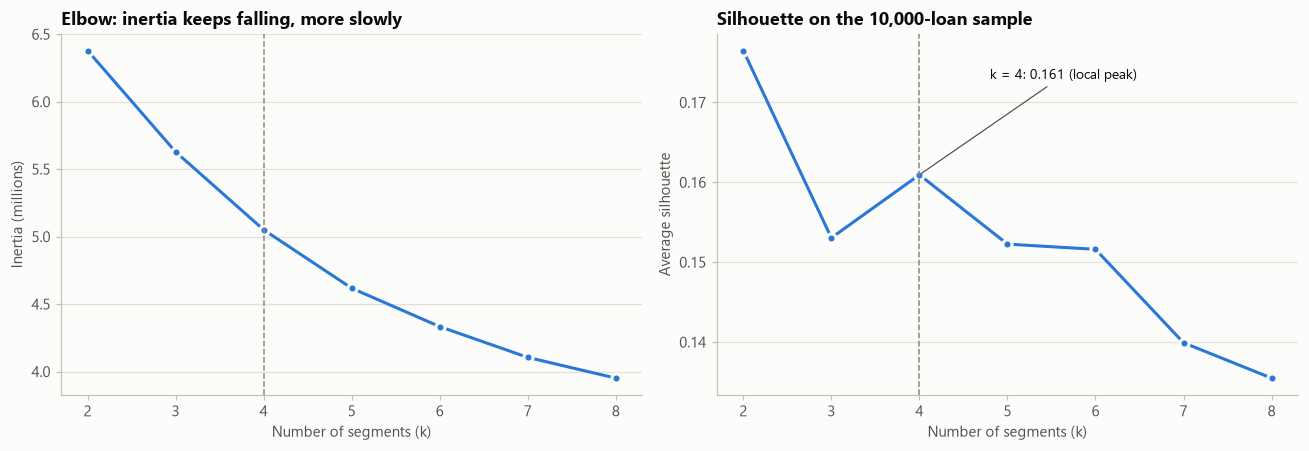

In [3]:
k_values = k_table.index.to_numpy()
chosen_silhouette = k_table.loc[N_SEGMENTS, "silhouette"]
marker_style = {"marker": "o", "markersize": 6,
                "markeredgecolor": SURFACE, "markeredgewidth": 2}

fig, (ax_elbow, ax_sil) = plt.subplots(1, 2, figsize=(12, 4.2))
ax_elbow.plot(k_values, k_table["inertia"] / 1e6, color=PRIMARY_COLOR,
              **marker_style)
ax_elbow.set_title("Elbow: inertia keeps falling, more slowly")
ax_elbow.set_ylabel("Inertia (millions)")

ax_sil.plot(k_values, k_table["silhouette"], color=PRIMARY_COLOR,
            **marker_style)
ax_sil.annotate(f"k = {N_SEGMENTS}: {chosen_silhouette:.3f} (local peak)",
                xy=(N_SEGMENTS, chosen_silhouette),
                xytext=(N_SEGMENTS + 0.8, chosen_silhouette + 0.012),
                fontsize=9, color=TEXT_PRIMARY,
                arrowprops={"arrowstyle": "-", "color": TEXT_SECONDARY,
                            "lw": 0.8})
ax_sil.set_title("Silhouette on the 10,000-loan sample")
ax_sil.set_ylabel("Average silhouette")

for ax in (ax_elbow, ax_sil):
    ax.axvline(N_SEGMENTS, color=TEXT_MUTED, linestyle="--", linewidth=1)
    ax.set_xticks(k_values)
    ax.set_xlabel("Number of segments (k)")
    ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_kmeans_choose_k.png")
plt.show()

**How to read the output.**
- **Elbow (left).** Inertia always falls as *k* grows, because more centres sit closer to their loans. There is **no sharp elbow**: each extra segment saves a little less than the one before (drops of 0.751, 0.577, 0.433, 0.285 million …), and the bend is spread over *k* = 4–5.
- **Silhouette (right).** The scores are low for every *k* (0.135–0.176): borrowers do not form well-separated islands, and section 4 shows why. *k* = 2 scores highest (0.176), but it only splits the loans into "bigger" and "smaller" borrowers along PC1 (higher vs lower income and loan amount), which is too coarse to act on. **k = 4 is a local peak (0.161)**, better than both *k* = 3 (0.153) and *k* = 5 (0.152).
- **Smallest segment.** At *k* = 4 the smallest segment still holds 12.7% of the loans (171,515 loans), large enough for a product or a policy.

**Decision: k = 4.** It is a local silhouette peak, it sits inside the elbow's bend, and four segments are easy to describe (section 6).

### 2.2 The final K-Means model (k = 4, all loans)

K-Means numbers its clusters 0–3 in an arbitrary order. We renumber them **1–4 in order of PC1 (financial capacity)**: segment 1 has the lowest PC1, segment 4 the highest. The numbers then mean the same thing every time the notebook runs.

In [4]:
start = time.time()
kmeans = fit_kmeans(features, N_SEGMENTS)
segment_of_label = segment_numbers(kmeans)   # K-Means label -> segment 1-4
segments = segment_of_label[kmeans.labels_]  # the segment of every loan
sample_segments = segments[positions]        # the same 10,000 sample loans
print(f"Fitted on all loans in {time.time() - start:.0f} s | "
      f"inertia {kmeans.inertia_:,.0f}")

centres = pd.DataFrame(kmeans.cluster_centers_,
                       columns=[f"PC{i}" for i in range(1, 8)],
                       index=pd.Index(segment_of_label, name="segment"))
centres = centres.sort_index()
segment_sizes = pd.Series(segments).value_counts().sort_index()
centres.insert(0, "share_%", (100 * segment_sizes / len(segments)).values)
centres.round(2)

Fitted on all loans in 21 s | inertia 5,050,972


,share_%,PC1,PC2,PC3,PC4,PC5,PC6,PC7
segment,,,,,,,,
1,32.90,-1.10,-0.36,-0.57,0.19,-0.00,0.01,-0.00
2,32.26,-0.20,0.64,0.50,-0.59,-0.10,-0.03,0.03
3,12.73,0.59,-1.08,1.23,0.92,-0.07,-0.03,0.06
4,22.11,1.59,0.23,-0.60,0.06,0.19,0.05,-0.07


**How to read the output.** Each row is one segment's centre in PCA space (units: standard deviations along each component, where 0 is the portfolio average).
- **Sizes:** 32.9%, 32.3%, 12.7% and 22.1% of all loans.
- **PC1 (financial capacity)** rises from segment 1 (−1.10) to segment 4 (+1.59), as the renumbering guarantees.
- **Segment 2** is high on PC2 (debt burden, +0.64). **Segment 3** is low on PC2 (−1.08) and high on PC3 and PC4, the components where FICO loads most.
- **PC6 and PC7** (the pure housing and purpose contrasts) are close to 0 for every centre. The segments are driven by **financial** characteristics; the housing and purpose differences you will see in section 6 come along with those.

### 2.3 Is the segmentation stable?

A segmentation that changed with the random seed would be hard to trust. We refit K-Means with two other seeds and count how many loans land in the same segment (after matching the numbering with `match_to_reference()`, explained in section 3.2).

In [5]:
for seed in [0, 7]:
    other_run = fit_kmeans(features, N_SEGMENTS, seed=seed)
    _, agreement = match_to_reference(segments, other_run.labels_)
    print(f"seed {seed}: {agreement:.1%} of loans in the same segment")

seed 0: 99.5% of loans in the same segment
seed 7: 100.0% of loans in the same segment


**How to read the output.** With seeds 0 and 7, **99.5%** and **100.0%** of the loans land in the same segment as with seed 42. The segments are a stable feature of the data, not the luck of the starting centres.

## 3. Hierarchical clustering (Ward linkage)

**Concept.** *Agglomerative* hierarchical clustering starts with every loan as its own cluster and repeatedly **merges the two closest clusters** until a single cluster is left. The merge history is a tree called a **dendrogram**; cutting it at a chosen height gives the clusters. **Ward linkage** always merges the pair of clusters that increases the total within-cluster variance the least. That is the same quantity K-Means minimises, so the two methods can be compared fairly.

**Why a sample?** It needs the distance between every pair of loans. For 10,000 loans that is 50 million distances (about 400 MB of memory); for all 1.35 million it would be about 908 billion (over 7 TB). So hierarchical clustering runs on the shared 10,000-loan sample.

### 3.1 Build the tree and draw the dendrogram

Ward linkage on 10,000 loans in 10.6 s
Heights of the last 6 merges (final merge first): [126.5  89.7  89.3  74.6  68.5  59.6]


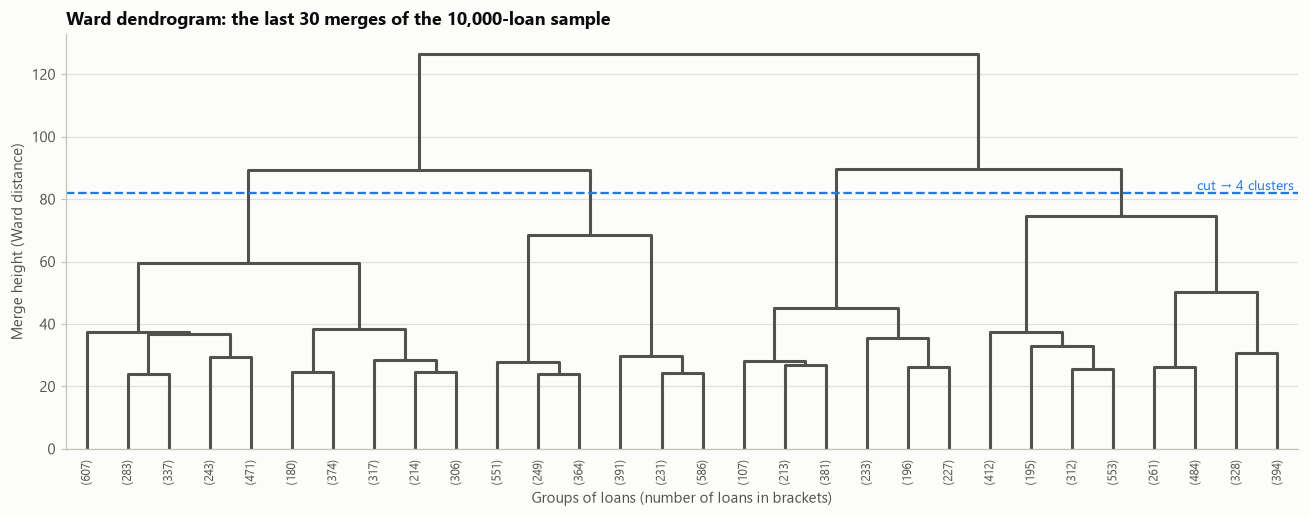

In [6]:
start = time.time()
ward_tree = linkage(sample_features, method="ward")
print(f"Ward linkage on {len(sample_features):,} loans "
      f"in {time.time() - start:.1f} s")

# Each row of ward_tree is one merge; column 2 is the merge height.
last_heights = ward_tree[::-1, 2][:6]
print("Heights of the last 6 merges (final merge first):",
      np.round(last_heights, 1))

# A horizontal cut between the merges that leave 5 and 4 clusters
# crosses exactly 4 branches.
cut_height = (ward_tree[-N_SEGMENTS, 2] + ward_tree[-N_SEGMENTS + 1, 2]) / 2

fig, ax = plt.subplots(figsize=(12, 4.8))
dendrogram(ward_tree, truncate_mode="lastp", p=30, ax=ax,
           color_threshold=0, above_threshold_color=TEXT_SECONDARY,
           leaf_rotation=90, leaf_font_size=8)
ax.axhline(cut_height, color=PRIMARY_COLOR, linestyle="--", linewidth=1.5)
ax.text(ax.get_xlim()[1], cut_height, f"cut → {N_SEGMENTS} clusters ",
        ha="right", va="bottom", fontsize=9, color=PRIMARY_COLOR)
ax.set_title("Ward dendrogram: the last 30 merges of the 10,000-loan sample")
ax.set_xlabel("Groups of loans (number of loans in brackets)")
ax.set_ylabel("Merge height (Ward distance)")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_ward_dendrogram.png")
plt.show()

**How to read the dendrogram.** Each ∩-shaped link is a merge, and its height shows how different the two merged groups were. A **big jump** in height means two quite different groups were forced together, so a good place to cut is just below a big jump.
- The biggest jump is the final merge (89.7 → 126.5): the data splits most easily into two broad groups, just as K-Means scored its highest silhouette at *k* = 2.
- The next clear gap lies between 74.6 and 89.3. The dashed line cuts there and crosses **4 branches**, matching the K-Means choice, so the two algorithms can be compared like for like. (Between 3 and 4 clusters there is almost no gap: 89.3 vs 89.7.)

### 3.2 Cut the tree into 4 clusters and compare with K-Means

Ward numbers its clusters in its own order, so we give each Ward cluster the number of the K-Means segment it overlaps most (`match_to_reference()` in `src/clustering.py`). Agreement then sits on the diagonal of the table.

In [7]:
ward_raw = fcluster(ward_tree, t=N_SEGMENTS, criterion="maxclust")
ward_labels, ward_agreement = match_to_reference(sample_segments, ward_raw)
print(f"Ward puts {ward_agreement:.1%} of the sample loans "
      "in the same segment as K-Means")

pd.crosstab(pd.Series(sample_segments, name="K-Means segment"),
            pd.Series(ward_labels, name="Ward cluster (matched)"),
            margins=True, margins_name="total")

Ward puts 73.4% of the sample loans in the same segment as K-Means


Ward cluster (matched),1,2,3,4,total
K-Means segment,,,,,
1,2591,156,88,464,3299
2,427,2030,201,561,3219
3,246,74,885,85,1290
4,68,112,183,1829,2192
total,3332,2372,1357,2939,10000


**How to read the output.** Rows are K-Means segments and columns are the matched Ward clusters, so the diagonal counts the loans both algorithms put in the same group: **about 73.4%** of the sample. Ward finds broadly the same four groups but draws some borders differently. The biggest disagreement is K-Means segment 2: about 560 of its loans go to Ward's cluster 4 and about 430 to cluster 1. Segment 2 sits in the middle of the cloud, so its borders are the least clear-cut.

## 4. DBSCAN (density-based clustering)

**Concept.** DBSCAN looks at a neighbourhood of radius `eps` around every loan.
- A **core point** has at least `min_samples` loans (itself included) inside its neighbourhood.
- Core points within `eps` of each other are chained into one **cluster**, together with the loans next to them.
- Loans that are not near any core point are labelled **noise** (−1): they sit in sparse regions, away from everyone else.

DBSCAN does not need *k*, can find clusters of any shape, and flags outliers. But it can only separate two clusters if there is an **empty (low-density) gap** between them.

### 4.1 Choosing `min_samples` and `eps`
- `min_samples = 14`: the common rule of thumb of 2 × the number of features (7 PCA components).
- `eps` from the **k-distance plot**: for every loan, the distance to its 14th nearest neighbour, sorted from smallest to largest. Most loans have close neighbours; at the **knee**, where the curve shoots up, the remaining loans are far more isolated. The distance at the knee is a natural `eps`, and `find_knee()` locates it as the point furthest below the straight line joining the two ends of the curve.

Knee at loan 9,592 of 10,000 -> eps = 1.46


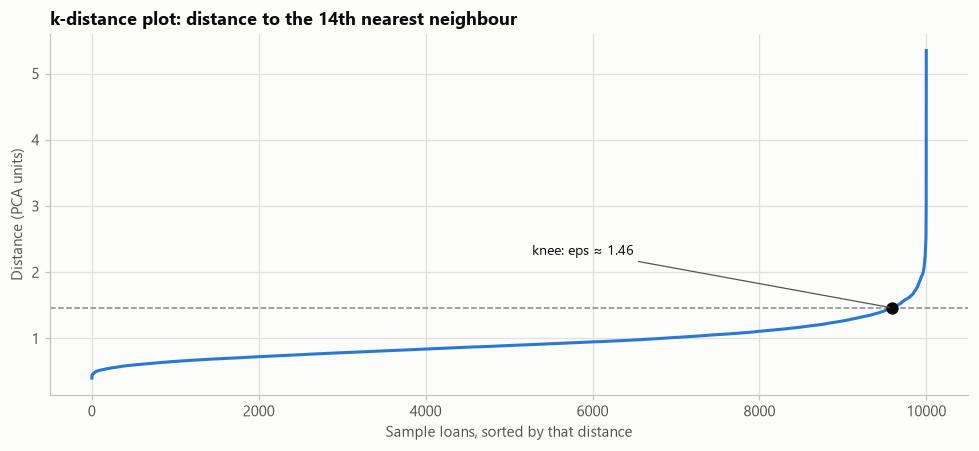

In [8]:
k_distances = k_distance_curve(sample_features, DBSCAN_MIN_SAMPLES)
knee = find_knee(k_distances)
eps = round(float(k_distances[knee]), 2)
print(f"Knee at loan {knee:,} of {len(k_distances):,} -> eps = {eps}")

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(k_distances, color=PRIMARY_COLOR)
ax.scatter([knee], [k_distances[knee]], s=50, color=TEXT_PRIMARY, zorder=3)
ax.axhline(eps, color=TEXT_MUTED, linestyle="--", linewidth=1)
ax.annotate(f"knee: eps ≈ {eps}", xy=(knee, k_distances[knee]),
            xytext=(knee * 0.55, k_distances[knee] + 0.8), fontsize=9,
            color=TEXT_PRIMARY,
            arrowprops={"arrowstyle": "-", "color": TEXT_SECONDARY,
                        "lw": 0.8})
ax.set_title(f"k-distance plot: distance to the {DBSCAN_MIN_SAMPLES}th "
             "nearest neighbour")
ax.set_xlabel("Sample loans, sorted by that distance")
ax.set_ylabel("Distance (PCA units)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_dbscan_k_distance.png")
plt.show()

**How to read the chart.** The curve rises slowly for about 96% of the loans (their 14th neighbour is within about 1.4 units), then shoots up for the last few hundred: those loans are far from everyone else. The knee gives **eps ≈ 1.46**.

### 4.2 Run DBSCAN

In [9]:
dbscan_labels = DBSCAN(eps=eps, min_samples=DBSCAN_MIN_SAMPLES).fit_predict(
    sample_features)
dbscan_info = describe_clusters(dbscan_labels)
n_noise = int((dbscan_labels == NOISE).sum())
print(f"Clusters: {dbscan_info['clusters']} | "
      f"largest cluster: {dbscan_info['largest_cluster_%']:.1f}% "
      f"of the sample | noise: {n_noise} loans "
      f"({dbscan_info['noise_%']:.1f}%)")

Clusters: 1 | largest cluster: 99.2% of the sample | noise: 77 loans (0.8%)


**How to read the output.** With the knee `eps`, DBSCAN puts **99.2%** of the sample into **one cluster** and labels **77 loans (0.8%) as noise**. It does not split the borrowers into segments at all.

### 4.3 Is there an `eps` that gives a few real segments?

If dense groups were separated by gaps, some smaller `eps` would split them apart. We try a range of values below the knee.

In [10]:
eps_scan = dbscan_eps_scan(sample_features,
                           [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.2, eps])
eps_scan.round(1)

,clusters,noise_%,smallest_cluster_%,largest_cluster_%
eps,,,,
0.50,6,97.3,0.1,1.7
0.60,8,86.3,0.0,6.6
0.70,9,65.3,0.1,14.8
0.80,6,41.6,0.1,40.4
0.90,1,23.7,76.3,76.3
1.00,1,13.0,87.0,87.0
1.20,1,3.8,96.2,96.2
1.46,1,0.8,99.2,99.2


At `eps = 0.8` two larger clusters appear. What do they contain? We look at the loan purposes inside the two largest clusters.

In [11]:
labels_08 = DBSCAN(eps=0.8, min_samples=DBSCAN_MIN_SAMPLES).fit_predict(
    sample_features)
sizes_08 = pd.Series(labels_08[labels_08 != NOISE]).value_counts()
in_two_largest = np.isin(labels_08, sizes_08.index[:2])
purpose_08 = 100 * pd.crosstab(
    pd.Series(labels_08[in_two_largest], name="cluster at eps 0.8"),
    group_purpose(loans["purpose"].iloc[positions[in_two_largest]]).values,
    normalize="index",
).rename_axis(columns=None)
purpose_08.insert(0, "share_of_sample_%",
                  100 * sizes_08.loc[purpose_08.index].to_numpy()
                  / len(labels_08))
purpose_08.round(1)

,share_of_sample_%,credit_card,debt_consolidation,home,personal_other,small_business
cluster at eps 0.8,,,,,,
0,40.4,0.0,100.0,0.0,0.0,0.0
1,17.5,55.9,0.0,13.6,28.3,2.2


**How to read the outputs.**
- **eps 0.5–0.7:** most loans become noise (65–97%) and the rest break into 6–9 clusters: the neighbourhoods are too small for the data's density.
- **eps 0.8:** two larger clusters appear (40.4% and 17.5% of the sample), but **41.6% of the loans are left as noise**. The second table shows what they are: one is **100% debt-consolidation loans** and the other contains **no** debt-consolidation loans at all. DBSCAN is picking up the loan-purpose categories, as the t-SNE map did in notebook 03, not financial segments.
- **eps 0.9 and above:** everything joins **one** cluster; only the amount of noise shrinks.

**Conclusion.** No `eps` gives a few sizeable segments without throwing away a large part of the portfolio. The loans form **one continuous dense cloud**: profiles change gradually from one borrower to the next, with no empty gaps. This is also why the silhouette scores of K-Means and Ward are low.

DBSCAN is therefore not the right tool to *segment* this portfolio, but it is useful in another way: its **noise points** are borrowers in sparse regions, in other words **unusual profiles**. Notebook 05 investigates them for Stage 9 (anomaly detection).

---
# Stage 7 — Cluster Evaluation and Interpretation

## 5. Comparing K-Means, Hierarchical clustering and DBSCAN

All three algorithms are scored on **the same 10,000 loans** with the same metrics. For DBSCAN the silhouette leaves out the noise points, and it needs at least two clusters.

In [12]:
comparison = pd.DataFrame([
    {"algorithm": "K-Means",
     "settings": f"k = {N_SEGMENTS}, 10 starts, fitted on all loans",
     **cluster_quality(sample_features, sample_segments),
     "agreement_with_kmeans_%": 100.0,
     "labels_all_loans": "yes"},
    {"algorithm": "Hierarchical (Ward)",
     "settings": f"tree cut at {N_SEGMENTS} clusters, 10,000-loan sample",
     **cluster_quality(sample_features, ward_labels),
     "agreement_with_kmeans_%": 100 * ward_agreement,
     "labels_all_loans": "no (memory grows with the square of n)"},
    {"algorithm": "DBSCAN",
     "settings": (f"eps = {eps}, min_samples = {DBSCAN_MIN_SAMPLES}, "
                  "10,000-loan sample"),
     **cluster_quality(sample_features, dbscan_labels),
     "agreement_with_kmeans_%": np.nan,
     "labels_all_loans": "no"},
]).set_index("algorithm")
comparison.round(3).to_csv(CLUSTER_COMPARISON_FILE)
comparison.drop(columns="settings").round(3)

,clusters,noise_%,smallest_cluster_%,largest_cluster_%,silhouette,agreement_with_kmeans_%,labels_all_loans
algorithm,,,,,,,
K-Means,4,0.00,12.90,32.99,0.161,100.00,yes
Hierarchical (Ward),4,0.00,13.57,33.32,0.094,73.35,no (memory grows with the square of n)
DBSCAN,1,0.77,99.23,99.23,NaN,NaN,no


**How to read the table.**
- **Silhouette:** K-Means **0.161** is clearly better than Ward **0.094**. DBSCAN has no score because it found only one cluster.
- **Cluster sizes:** K-Means and Ward both give four sizeable groups (the smallest about 13% of loans). DBSCAN puts 99% of the loans into one cluster.
- **Agreement:** Ward puts 73.4% of the loans in the same segment as K-Means, so the four-segment structure is not an accident of one algorithm.
- **Scalability:** only K-Means can label all 1.35 million loans, and it can also assign a new applicant to a segment.

**Decision: K-Means with k = 4 is the final segmentation.** Ward is the cross-check that confirms its structure; DBSCAN's noise points feed the anomaly detection in notebook 05. The table is saved as `reports/clustering_comparison.csv` for the clustering analysis report.

The three results on the PCA map (PC1 × PC2) of the shared sample:

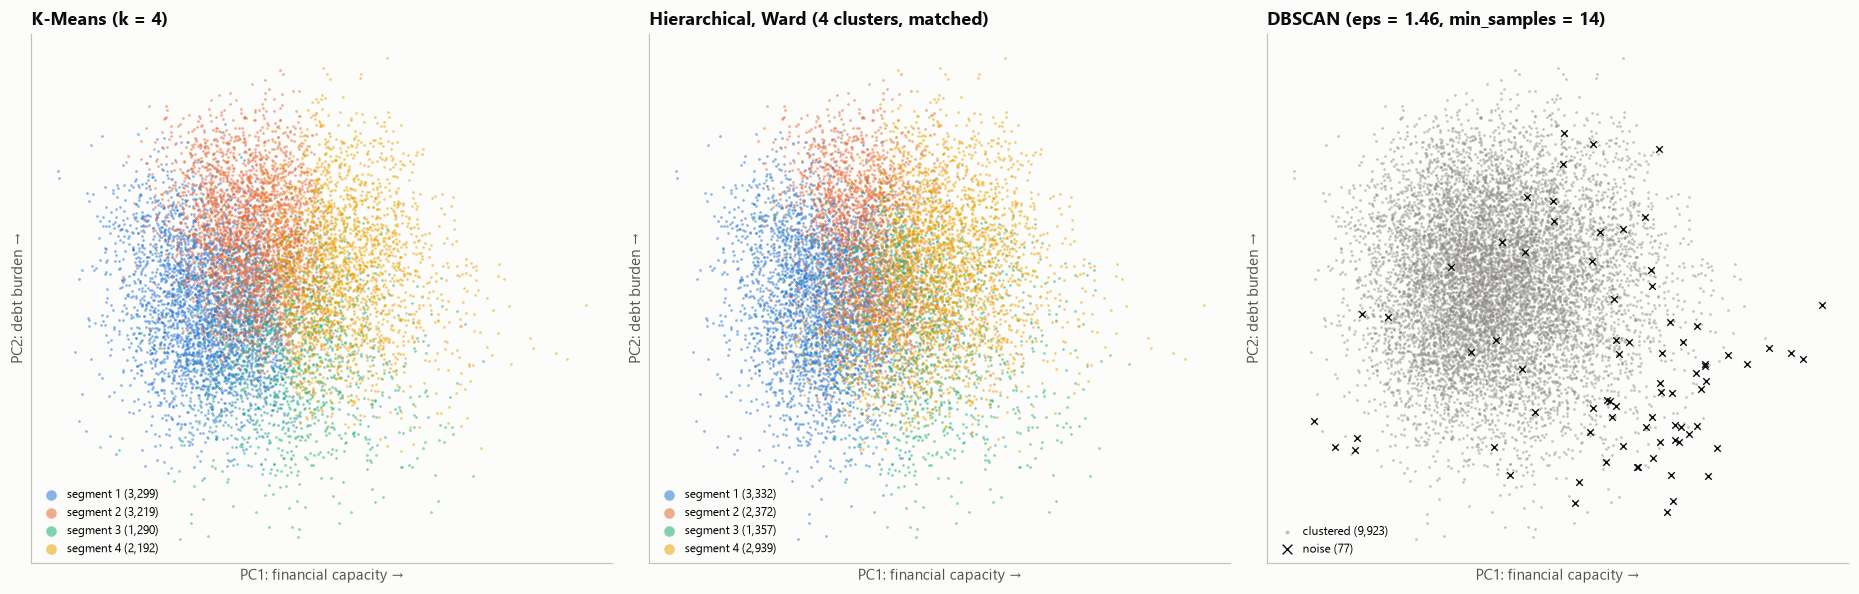

In [13]:
pca_coords = map_sample[["pc1", "pc2"]].to_numpy()
number_names = {s: f"segment {s}" for s in range(1, N_SEGMENTS + 1)}

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
plot_segment_map(axes[0], pca_coords, sample_segments, number_names,
                 f"K-Means (k = {N_SEGMENTS})")
plot_segment_map(axes[1], pca_coords, ward_labels, number_names,
                 f"Hierarchical, Ward ({N_SEGMENTS} clusters, matched)")
plot_dbscan_map(axes[2], pca_coords, dbscan_labels,
                f"DBSCAN (eps = {eps}, min_samples = {DBSCAN_MIN_SAMPLES})")
for ax in axes:
    ax.set_xlabel("PC1: financial capacity →")
    ax.set_ylabel("PC2: debt burden →")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_algorithms_on_pca_map.png")
plt.show()

**How to read the maps.**
- **K-Means** divides the cloud into four neighbouring regions: segment 1 on the left (low PC1), segment 4 on the right (high PC1), segment 2 in the upper middle (higher debt burden) and segment 3 at the bottom (lower debt burden).
- **Ward** produces a similar layout, with the borders in slightly different places.
- **DBSCAN** sees one big cloud. Most of its 77 noise points (black crosses) sit on the **outer edge**, especially on the right (very high financial capacity): borrowers with unusual combinations of income, loan size, DTI, FICO or employment.

Remember that this map shows only 2 of the 7 dimensions the algorithms used. That is why the borders look blurred and why a few noise points appear inside the cloud: they are unusual in the other 5 dimensions.

## 6. Segment profiles — who is in each segment?

**Concept.** *Profiling* describes each segment with the original, readable features (dollars, FICO points, percentages) instead of PCA units. This is the project's **cluster interpretability** check: a segmentation is only useful if a lender can say who is in each segment and how the segments differ.

### 6.1 Profile table (all 1,347,681 loans)

In [14]:
profiles = segment_profiles(loans, segments)

portfolio = {
    "median income": loans["revenue"].median(),
    "median loan": loans["loan_amnt"].median(),
    "mean FICO": loans["fico_n"].mean(),
    "median DTI": loans["dti_n"].median(),
    "mean employment years": loans["emp_length_years"].mean(),
}
print("Portfolio: " + ", ".join(f"{name} {value:,.1f}"
                                for name, value in portfolio.items()))
profiles.round(1).T

Portfolio: median income 65,000.0, median loan 12,000.0, mean FICO 698.2, median DTI 17.6, mean employment years 6.0


segment,1,2,3,4
loans,443419.0,434783.0,171515.0,297964.0
share_%,32.9,32.3,12.7,22.1
median_income,48576.0,60139.0,70000.0,109000.0
median_loan,9600.0,10650.0,12000.0,25000.0
mean_fico,686.7,686.4,758.4,697.6
median_dti,18.1,19.4,13.6,16.7
mean_emp_years,2.4,9.2,6.1,6.3
emp_unknown_%,7.8,4.9,7.5,3.2
mortgage_%,28.3,55.6,58.5,66.9
rent_%,60.7,33.3,29.1,24.1


**How to read the output.** One column per segment; compare each value with the portfolio line printed above (median income \$65,000, median loan \$12,000, mean FICO 698, median DTI 17.6%, mean employment 6.0 years). Medians are used for income, loan amount and DTI because they are skewed; means for FICO and employment years.
- **Segment 1 (32.9%)** has the **lowest income** (median \$48.6K) and the **smallest loans** (\$9.6K), the **shortest time in the current job** (2.4 years on average) and is the only segment where most borrowers **rent** (61%).
- **Segment 2 (32.3%)** has the **longest employment** (9.2 years) and the **highest DTI** (19.4%), with income (\$60K) and FICO (686) slightly below average.
- **Segment 3 (12.7%)** has by far the **best credit scores** (mean FICO 758, 60 points above average) and the **lowest DTI** (13.6%). It also has the fewest debt-consolidation loans (48%) and the most home-improvement and other personal loans.
- **Segment 4 (22.1%)** has the **highest income** (median \$109K) and the **largest loans** (median \$25,000, about twice the portfolio median); 67% have a mortgage; its FICO (698) is average.
- The share of unreported employment is 3–8% in every segment, and home ownership OTHER (517 loans in total) is left out of the table because it is about 0% everywhere.

### 6.2 Naming the segments

A name should say what makes a segment **different from the average**, using only the evidence above. The names describe borrower characteristics, not risk: risk is measured in notebook 05.

In [15]:
SEGMENT_NAMES = {
    1: "Short-tenure renters",
    2: "Long-tenure, higher DTI",
    3: "Prime credit, low DTI",
    4: "High income, large loans",
}

# Each name rests on these facts. If a re-run ever produced different
# profiles, the notebook stops here instead of showing wrong names.
name_checks = {
    "1 has the lowest income": profiles["median_income"].idxmin() == 1,
    "1 has the shortest employment": profiles["mean_emp_years"].idxmin() == 1,
    "1 is mostly renters": profiles.loc[1, "rent_%"] > 50,
    "2 has the longest employment": profiles["mean_emp_years"].idxmax() == 2,
    "2 has the highest DTI": profiles["median_dti"].idxmax() == 2,
    "3 has the highest FICO": profiles["mean_fico"].idxmax() == 3,
    "3 has the lowest DTI": profiles["median_dti"].idxmin() == 3,
    "4 has the highest income": profiles["median_income"].idxmax() == 4,
    "4 has the largest loans": profiles["median_loan"].idxmax() == 4,
}
failed = [check for check, passed in name_checks.items() if not passed]
if failed:
    raise ValueError(f"Profiles differ from the tested run: {failed}. "
                     "Re-read the profile table and update the names.")
profiles.insert(0, "name", pd.Series(SEGMENT_NAMES))
print(f"All {len(name_checks)} naming checks passed")
profiles[["name", "loans", "share_%"]].round(1)

All 9 naming checks passed


,name,loans,share_%
segment,,,
1,Short-tenure renters,443419,32.9
2,"Long-tenure, higher DTI",434783,32.3
3,"Prime credit, low DTI",171515,12.7
4,"High income, large loans",297964,22.1


**How to read the output.** All nine facts behind the names hold, so the names are backed by evidence. If you re-ran the notebook on different data and a fact no longer held, the cell would stop with a message instead of quietly showing a misleading name.

### 6.3 Profile heatmap

The heatmap shows the same profiles at a glance. The **colour** is the segment's average of each *standardised* feature: what K-Means actually saw, in standard deviations (SD) from the portfolio average (red = above, blue = below). The **text** is the typical value in real units, from the profile table.

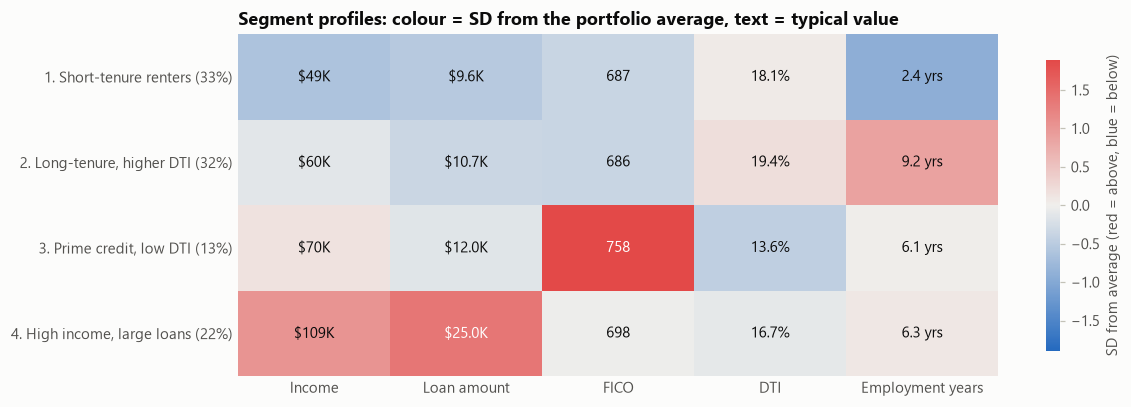

,Income,Loan amount,FICO,DTI,Employment years
1. Short-tenure renters (33%),-0.61,-0.53,-0.36,0.05,-0.91
"2. Long-tenure, higher DTI (32%)",-0.13,-0.35,-0.37,0.19,0.86
"3. Prime credit, low DTI (13%)",0.14,-0.14,1.89,-0.45,0.03
"4. High income, large loans (22%)",1.02,1.37,-0.02,-0.09,0.08


In [16]:
with open(FEATURE_PIPELINE_FILE, "rb") as file:
    feature_pipeline = pickle.load(file)
preprocess = feature_pipeline.named_steps["preprocess"]

# The 15 columns from notebook 03, before PCA (the same transformation).
encoded = pd.DataFrame(
    preprocess.transform(prepare_feature_frame(loans)),
    columns=preprocess.get_feature_names_out(),
)
numeric_names = {"log_income": "Income", "loan_amount": "Loan amount",
                 "fico": "FICO", "dti": "DTI",
                 "emp_length_years": "Employment years"}
z_scores = (encoded[list(numeric_names)].groupby(segments).mean()
            .rename(columns=numeric_names))
z_scores.index = [
    f"{s}. {SEGMENT_NAMES[s]} ({profiles.loc[s, 'share_%']:.0f}%)"
    for s in z_scores.index
]

cell_text = pd.DataFrame({
    "Income": profiles["median_income"].map(lambda v: f"${v / 1e3:.0f}K"),
    "Loan amount": profiles["median_loan"].map(lambda v: f"${v / 1e3:.1f}K"),
    "FICO": profiles["mean_fico"].map(lambda v: f"{v:.0f}"),
    "DTI": profiles["median_dti"].map(lambda v: f"{v:.1f}%"),
    "Employment years": profiles["mean_emp_years"].map(
        lambda v: f"{v:.1f} yrs"),
})

fig, ax = plt.subplots(figsize=(11, 3.8))
image = plot_profile_heatmap(ax, z_scores, cell_text,
                             "Segment profiles: colour = SD from the "
                             "portfolio average, text = typical value")
colour_bar = fig.colorbar(image, ax=ax, shrink=0.85)
colour_bar.set_label("SD from average (red = above, blue = below)")
colour_bar.outline.set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_segment_profiles.png")
plt.show()
z_scores.round(2)

**How to read the heatmap.** Each row is a segment's "fingerprint".
- **Prime credit, low DTI** has the strongest colour in the chart: FICO +1.89 SD (red), with DTI −0.45 SD (blue).
- **High income, large loans** is red for loan amount (+1.37 SD) and income (+1.02 SD) and average for FICO (−0.02).
- **Short-tenure renters** is blue for employment years (−0.91), income (−0.61) and loan amount (−0.53), and slightly blue for FICO (−0.36).
- **Long-tenure, higher DTI** is red for employment years (+0.86) and blue for FICO and loan amount (about −0.36). It has the highest DTI of the four segments, although only 0.19 SD above average.

Every segment differs from the average in its own combination of features, which is what makes the segments **interpretable**. Notice that no segment is defined by a single feature.

### 6.4 The segments on the PCA, t-SNE and UMAP maps

The project asks for PCA, t-SNE and UMAP plots *to explore borrower segments*. We colour the maps from notebook 03 by K-Means segment; the coordinates come from `map_sample.pkl`, so nothing is recomputed.

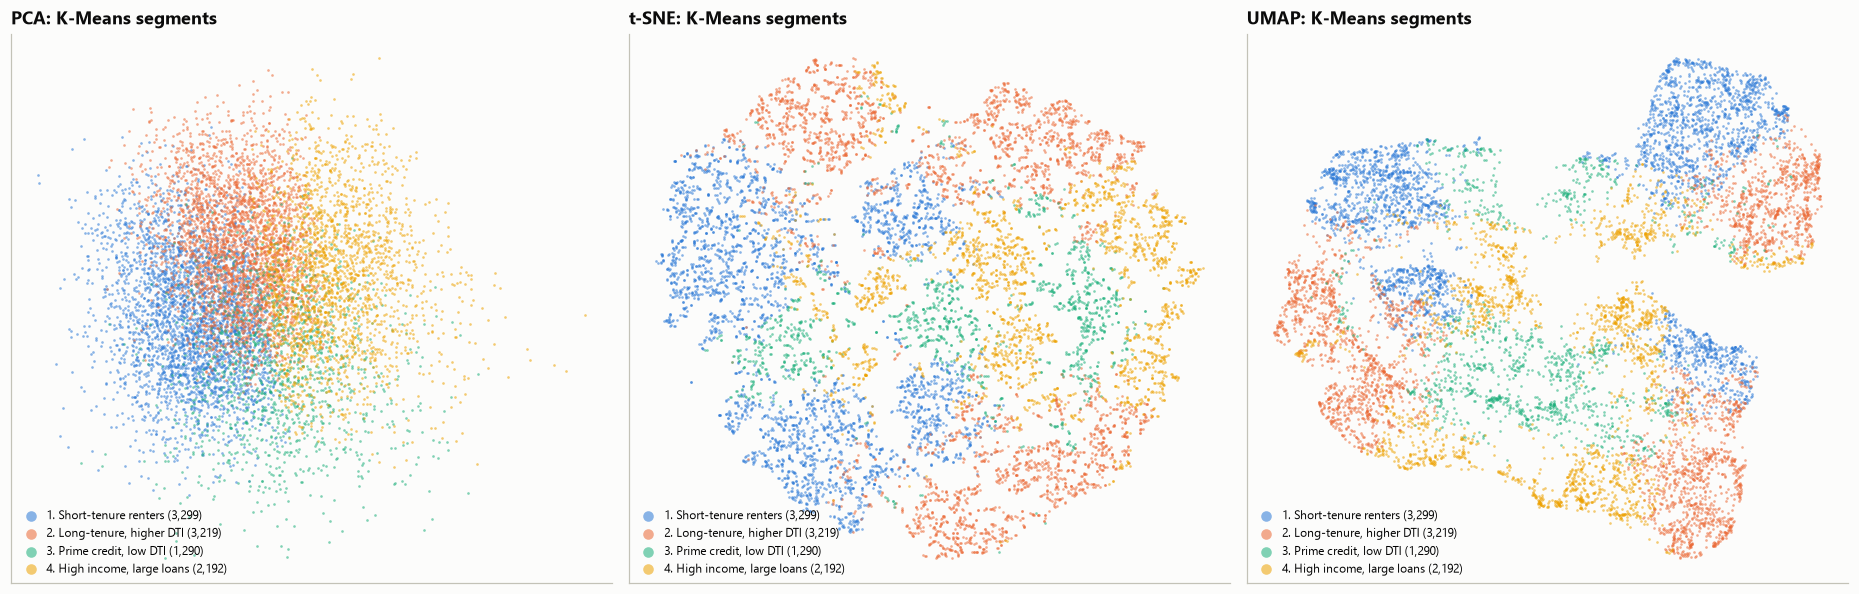

In [17]:
segment_legend = {s: f"{s}. {name}" for s, name in SEGMENT_NAMES.items()}
map_columns = {"PCA": ["pc1", "pc2"], "t-SNE": ["tsne_1", "tsne_2"],
               "UMAP": ["umap_1", "umap_2"]}

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, (method, columns) in zip(axes, map_columns.items()):
    plot_segment_map(ax, map_sample[columns].to_numpy(), sample_segments,
                     segment_legend, f"{method}: K-Means segments")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_segments_on_maps.png")
plt.show()

**How to read the maps.**
- **PCA:** the four segments occupy four neighbouring regions of the cloud. PCA's axes are the directions of greatest variance, and K-Means cuts along them.
- **t-SNE:** each segment appears as **several separate zones** rather than one island. The map is still organised by home ownership and purpose (notebook 03), and every segment shows up inside several of those regions; the Short-tenure renters are concentrated where the renters are. t-SNE groups loans by their *nearest neighbours*, and the 0/1 categories create the strongest neighbourhoods, whereas K-Means groups by overall financial profile.
- **UMAP:** see exercise question 2 at the end.

The lesson: t-SNE and UMAP are for *looking*, not for defining segments. A segment does not have to be an island on a 2-D map to be real and useful.

## 7. Robustness check — would another feature design give better segments?

In notebook 03 (section 4.4) we kept the 0/1 category columns unscaled and promised to test the alternative here. We compare three designs, each segmented by K-Means (k = 4) on **all** loans and scored on the shared sample:

| Design | Columns used | Category columns |
|---|---|---|
| **A (ours)** | the 7 PCA components of the 15 columns | 0/1, not scaled |
| B | only the 5 scaled numeric columns | left out |
| C | all 15 columns standardised, then PCA keeping 90% of the variance | standardised like numbers |

In [18]:
start = time.time()
design_b = encoded[list(numeric_names)].to_numpy()
standardised = StandardScaler().fit_transform(encoded)
design_c = PCA(n_components=0.90,
               random_state=RANDOM_SEED).fit_transform(standardised)

design_labels = {"A (ours)": sample_segments}   # the model fitted above
for name, data in [("B: numeric only", design_b),
                   ("C: everything standardised", design_c)]:
    design_labels[name] = fit_kmeans(data, N_SEGMENTS).labels_[positions]
design_samples = {"A (ours)": sample_features,
                  "B: numeric only": design_b[positions],
                  "C: everything standardised": design_c[positions]}

design_table = pd.DataFrame({
    "columns": {name: data.shape[1] for name, data in design_samples.items()},
    "silhouette": {name: silhouette_score(design_samples[name], labels)
                   for name, labels in design_labels.items()},
})
print(f"Designs compared in {time.time() - start:.0f} s")
design_table.round(3)

Designs compared in 39 s


,columns,silhouette
A (ours),7,0.161
B: numeric only,5,0.194
C: everything standardised,11,0.211


In [19]:
# What are design C's segments made of? Share of each home-ownership type
# and purpose group inside every segment (rows add up to 100%).
sample_loans = loans.iloc[positions]
c_segments = pd.Series(design_labels["C: everything standardised"] + 1,
                       name="C segment")
home_mix = pd.crosstab(c_segments,
                       sample_loans["home_ownership_n"].astype(str).values,
                       normalize="index")
purpose_mix = pd.crosstab(c_segments,
                          group_purpose(sample_loans["purpose"]).values,
                          normalize="index")
(100 * pd.concat([home_mix, purpose_mix], axis=1)).rename_axis(
    columns=None).round(0)

,MORTGAGE,OTHER,OWN,RENT,credit_card,debt_consolidation,home,personal_other,small_business
C segment,,,,,,,,,
1,100.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0
2,99.0,0.0,0.0,0.0,50.0,0.0,23.0,23.0,3.0
3,0.0,0.0,100.0,0.0,23.0,53.0,10.0,13.0,1.0
4,0.0,0.0,0.0,100.0,23.0,59.0,2.0,15.0,1.0


**How to read the output.**
- **Silhouette:** design C scores the highest (0.211), then B (0.194), then our design A (0.161).
- **But look at what C's segments are:** they are **category groups**. One segment is all renters (100%), one is all outright owners (100%), and the mortgage holders are split into those consolidating debt (100% mortgage, 100% debt consolidation) and those borrowing for any other purpose (99% mortgage, 0% debt consolidation). Standardising the rare 0/1 columns made them dominate the distances, exactly as notebook 03 predicted, so C simply sorts loans by labels we already had. A higher silhouette here does not mean more insight.
- **Design B** ignores home ownership and purpose, which the project asks us to encode and use.

**Decision: keep design A.** Its silhouette is lower because it segments on financial characteristics that change gradually across borrowers, but its segments carry new, usable information. A metric is a guide, not the goal: a high silhouette for trivial clusters is worse than a moderate one for meaningful clusters.

## 8. Save the results

In [20]:
# 1. The segment of every loan (id + segment number): notebook 05 and the
#    dashboard join it to the loans.
segment_table = pd.DataFrame({ID_COLUMN: loans[ID_COLUMN].to_numpy(),
                              "segment": segments.astype("int8")})
segment_table.to_pickle(SEGMENTS_FILE)

# 2. The fitted K-Means model with its numbering and names, so a new
#    applicant can be assigned to a segment (dashboard, Stage 10).
with open(KMEANS_MODEL_FILE, "wb") as file:
    pickle.dump({"kmeans": kmeans, "segment_of_label": segment_of_label,
                 "segment_names": SEGMENT_NAMES}, file)

# 3. Every algorithm's labels for the shared sample (used in notebook 05).
cluster_sample = pd.DataFrame({"position": positions,
                               "kmeans_segment": sample_segments,
                               "ward_cluster": ward_labels,
                               "dbscan_label": dbscan_labels})
cluster_sample.to_pickle(CLUSTER_SAMPLE_FILE)

# 4. The cluster profiling table (the comparison table was saved in 5).
profiles.round(2).to_csv(SEGMENT_PROFILES_FILE)

for path in [SEGMENTS_FILE, KMEANS_MODEL_FILE, CLUSTER_SAMPLE_FILE,
             SEGMENT_PROFILES_FILE, CLUSTER_COMPARISON_FILE]:
    print(f"Saved {path.parent.name}/{path.name} "
          f"({path.stat().st_size / 1024:,.1f} KB)")

Saved processed/segments.pkl (11,845.8 KB)
Saved models/kmeans_segments.pkl (5,265.3 KB)
Saved processed/cluster_sample.pkl (313.4 KB)
Saved reports/segment_profiles.csv (0.7 KB)
Saved reports/clustering_comparison.csv (0.4 KB)


## Summary — Stages 6 and 7

| Step | Result |
|---|---|
| K-Means, choosing *k* | **k = 4**: local silhouette peak (0.161), inside the elbow's bend (no sharp elbow), smallest segment 12.7% |
| Hierarchical (Ward) | 4 clusters on the 10,000-loan sample; silhouette 0.094; **73.4% agreement** with K-Means |
| DBSCAN | `min_samples` 14, `eps` 1.46 (k-distance knee) → one dense cloud + 0.8% noise; no `eps` gives usable segments |
| Final segmentation | **K-Means**: best silhouette, confirmed by Ward, labels all 1.35 M loans |
| Segments | 1 Short-tenure renters (32.9%) · 2 Long-tenure, higher DTI (32.3%) · 3 Prime credit, low DTI (12.7%) · 4 High income, large loans (22.1%) |
| Robustness | Standardising the categories (design C) raises the silhouette (0.211) only by splitting loans by category labels → design A kept |
| `Default` | never loaded: dropped on reading, checked by an `assert` |
| Saved | `data/processed/segments.pkl`, `models/kmeans_segments.pkl`, `data/processed/cluster_sample.pkl`, `reports/segment_profiles.csv`, `reports/clustering_comparison.csv`, 6 figures `04_*.png` |

**Next:** Notebook 05 — historical default rates by segment (Stage 8) and anomaly detection (Stage 9).

---
## Your turn — exercise (about 10 minutes)

1. **Predict before you look.** Notebook 05 will reveal each segment's historical default rate. Using only the profiles in section 6 and the EDA findings from notebook 02 (the default rate falls as FICO and income rise and rises with DTI and loan amount; renters 23.2% vs mortgage holders 17.2%; unreported employment 27.0%), rank the four segments from the **lowest** to the **highest** expected default rate and give one reason for each. Write the ranking down; notebook 05 will check it.
2. **UMAP.** Look at the UMAP panel in section 6.4. Do the segments form separate regions, or do they run across the regions created by home ownership and purpose, as on the t-SNE map? What does that tell you about what UMAP "sees" compared with K-Means?
3. **In one sentence:** why did we keep feature design A even though design C had a higher silhouette score?

## Progress check

- [ ] The notebook ran from top to bottom without errors (saved with **Ctrl+S**).
- [ ] `reports/figures` has 6 new `04_*.png` charts, and `reports` has `segment_profiles.csv` and `clustering_comparison.csv`.
- [ ] You can explain why *k* = 4, why DBSCAN found one cluster, and why K-Means is the final model.
- [ ] Commit and push: `git add .` → `git commit -m "Stages 6-7: clustering, evaluation and segment profiles"` → `git push`.

---
## Viva practice — Stages 6 and 7

**1. How did you choose the number of segments?**
I fitted K-Means for k = 2 to 8 on all loans. The elbow curve has no sharp bend, so I used the silhouette on a shared 10,000-loan sample: k = 4 is a local peak (0.161, above k = 3 and k = 5). k = 2 scored higher but only split big from small borrowers, which is too coarse. Four segments are also easy to interpret, and the smallest still holds 12.7% of loans.

**2. A silhouette of 0.16 is low. Is the clustering bad?**
It means the segments overlap: borrower profiles change gradually rather than forming separate islands. DBSCAN confirmed there are no empty gaps in the data. Low silhouettes are normal for customer data; what matters is that the segments have clearly different profiles, and Ward found the same structure (73.4% agreement).

**3. What is the difference between inertia and silhouette?**
Inertia is the total squared distance from loans to their own centre, so it only measures compactness and always falls as k grows. The silhouette compares each loan's distance to its own cluster with its distance to the nearest other cluster, so it measures compactness and separation together, on a −1 to +1 scale.

**4. Why 10 starts and a fixed seed for K-Means?**
K-Means can get stuck in a poor solution depending on its starting centres. Ten k-means++ starts keep the best result, and the fixed seed (42) makes every run identical. Refitting with two other seeds put over 99% of the loans in the same segment (section 2.3).

**5. How does hierarchical clustering work, and why Ward linkage?**
It starts with every loan as its own cluster and repeatedly merges the closest pair, recording the merges in a dendrogram that we cut at the chosen height. Ward merges the pair that increases within-cluster variance the least, the same objective as K-Means, which makes the comparison fair.

**6. Why did you run hierarchical clustering and DBSCAN on a sample?**
Hierarchical clustering needs every pairwise distance: about 908 billion pairs for 1.35 million loans, over 7 TB of memory. The silhouette needs the same. A fixed 10,000-loan sample makes the comparison possible and fair, because every algorithm is scored on the same loans.

**7. How did you choose DBSCAN's parameters?**
min_samples = 14, twice the number of features (7 PCA components). eps came from the k-distance plot: each loan's distance to its 14th nearest neighbour, sorted; the knee (about 1.46) separates loans with close neighbours from isolated ones.

**8. DBSCAN found only one cluster. Did it fail?**
No, it gave an honest answer: the loans form one continuous dense cloud with no low-density gaps, so there is nothing for a density method to separate. Smaller eps values only produced mostly noise or purpose categories. Its noise points are useful as unusual borrower profiles for anomaly detection.

**9. How did you compare the three algorithms?**
On the same 10,000 loans: silhouette score, number and size of clusters, share of noise, agreement with K-Means, and whether the method can label every loan. K-Means won on silhouette and scalability, and Ward confirmed its structure.

**10. How did you name the segments? Aren't names subjective?**
Each name states what makes the segment differ from the portfolio average in the profile table (for example, segment 3 has the highest FICO and lowest DTI). The notebook checks the nine facts behind the names and stops if any fails. The names describe characteristics, not risk.

**11. Was `Default` used anywhere in this notebook?**
No. It is dropped when the data is loaded, an `assert` proves it, and `segment_profiles()` refuses a table that contains it. Default rates by segment are only computed in notebook 05, after the segments are fixed.

**12. Why not standardise the 0/1 columns? Design C had a higher silhouette.**
Because C's segments were just category groups (all renters, all outright owners, and mortgage holders split by whether they consolidate debt): the standardised rare columns dominated the distances. That raises the silhouette without telling us anything new. Design A finds financial segments that carry new information.